In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import json
import time
import numpy as np
from dotenv import load_dotenv
load_dotenv()

from google import genai
from google.genai import types
client = genai.Client()

## Step 1: Policy

In [20]:
orig_policy = "You are a content moderator at AcornChat, an internet platform for squirrels.\nOur policies are as follows:\n-*Be kind:* Don't insult, threaten, or pile on other squirrels.\n-*Keep locations private:* Don't share where food is stored or where a squirrel lives.\n-*No raids:* Don't organize or encourage taking food from another squirrel's cache.\n*No spam:* Don't advertise goods or services.\n-*No fake danger:* Don't post false predator or hazard warnings."
print(orig_policy)

policies = pd.DataFrame({
    'iteration': [0],
    'text': [orig_policy]
    })

You are a content moderator at AcornChat, an internet platform for squirrels.
Our policies are as follows:
-*Be kind:* Don't insult, threaten, or pile on other squirrels.
-*Keep locations private:* Don't share where food is stored or where a squirrel lives.
-*No raids:* Don't organize or encourage taking food from another squirrel's cache.
*No spam:* Don't advertise goods or services.
-*No fake danger:* Don't post false predator or hazard warnings.


## Step 2: Load in data + human / ground truth labels

In [21]:
df = pd.read_csv('../input/acornchat_comments.csv')
df.head()

,id,comment,label
0,c001,lol Sprocket you'd lose your own tail if it we...,0
1,c002,"If you want the feeder to yourself, just yell ...",1
2,c003,Clover's emergency stash is under the doormat ...,1
3,c004,Nutmeg I owe you one for the hawk warning yest...,0
4,c005,"Not a hawk, just Old Man Birch on the roof aga...",0


In [22]:
df = df.rename(columns={"comment": "content"})
df["violation"] = df["label"].astype(bool)
df['violation'].value_counts()

violation
False    300
True     200
Name: count, dtype: int64

In [23]:
# basic cleaning - remove rows with missing data, remove duplicates
df = df.sample(frac=1,random_state=12345).drop_duplicates(subset='content')

In [24]:
# separate out train and test - taking 1k for train, remainder for test
df_train = df[["id","content"]].iloc[:300]
df_test = df[["id","content"]].iloc[300:]

In [25]:
df_train.head()

,id,content
272,c273,"Clover, want to meet at the big oak tomorrow? ..."
244,c245,Nutmeg sleeps in the attic vent of the yellow ...
271,c272,"Anyone else get a weird DM selling ""premium ac..."
381,c382,"Happy new drey day, Fern! The maple by the pos..."
52,c053,"I'm stealing this tip, thanks Wren!"


## Step 3: Policy iteration on train data

In [26]:
# function to run classifier
def classify(policy,content):
    """
        input: 
            - policy, text of current policy
            - content, df with "content" field as text to classify and "id"
        output:
            - results, df with ID and classification
    """
    # create batch doc
    with open("../output/batch.json", "w") as f:
        for i in range(len(content)):
            f.write(json.dumps({
                "key": f"request-{i}", "request": {"contents": [{"parts": [{"text": policy + "\n\nReturn solely the text 'True' or 'False', depending on whether you identify the below content as a violation of our policies:\n\n" + content["content"].iloc[i]}]}]}
            }) + "\n")

    # upload and run batch
    uploaded_file = client.files.upload(file = "../output/batch.json", config=types.UploadFileConfig(display_name='class', mime_type='jsonl'))
    file_batch_job = client.batches.create(
        model="gemini-3.1-flash-lite",
        src=uploaded_file.name,
        config={
            'display_name': "file-upload-job-1",
        },
    )

    # check on batch
    completed_states = set(['JOB_STATE_SUCCEEDED','JOB_STATE_FAILED','JOB_STATE_CANCELLED','JOB_STATE_EXPIRED'])
    batch_job = client.batches.get(name=file_batch_job.name)
    while batch_job.state.name not in completed_states:
        time.sleep(30)
        batch_job = client.batches.get(name=file_batch_job.name)
    print(f"Job finished: {batch_job.state.name}")

    # get and interpret results
    output = client.files.download(file=batch_job.dest.file_name)
    with open("../output/batch_results.json", "wb") as f:
        f.write(output)
    with open("../output/batch_results.json", encoding="utf-8") as f:
        results = pd.DataFrame([
            {"key": int(r["key"].removeprefix("request-")),
            "classification": r["response"]["candidates"][0]["content"]["parts"][0]["text"]}
            for line in f
            if "candidates" in (r := json.loads(line))["response"]
        ])
    results["id"] = content["id"].iloc[results["key"]].values
    return results[["id","classification"]]
    

In [27]:
def upd_policy(policy, merged):
    with open("../output/refine.txt", "w", encoding="utf-8") as f:
        f.write("Your job is to refine an LLM classifier policy, geared towards moderation on an internet platform for squirrels. Below is the current policy, list of false positives, and list of false negatives. Return solely an updated version of the policy to catch the false negatives and not mark the false positives, bearing concision in mind.\n")
        f.write("CURRENT POLICY TEXT:\n" + policy + "\n\n")
        f.write("FALSE POSITIVES:\n-----\n")
        for content in merged.loc[merged["outcome"] == "FP", "content"]:
            f.write(f"{content}\n-----\n")
        f.write("\nFALSE NEGATIVES:\n-----\n")
        for content in merged.loc[merged["outcome"] == "FN", "content"]:
            f.write(f"\n{content}\n-----\n")
        f.write("REFINED POLICY:")
    with open("../output/refine.txt", "r", encoding="utf-8") as f:
        refine_prompt = f.read()
    interaction = client.interactions.create(
        model="gemini-3.8-flash",
        input=refine_prompt
    )
    return interaction.output_text

In [28]:
# runs iterations
iterations = 4
eval_df = pd.DataFrame({
    "iteration": [],
    "precision": [],
    "recall": [],
    "f1": [],
    "length": []
})

for i in range(iterations):
    print(f"Iteration {i}")
    # run classifier
    policy = policies["text"].iloc[-1]
    results = classify(policy, df_train)
    print("Classification complete.")

    # record stats
    results["truth"] = results["id"].map(df.set_index("id")["violation"])
    pred = results["classification"].str.strip().eq("True")
    results["outcome"] = np.where(pred == results["truth"].astype(bool), "T", "F") + np.where(pred, "P", "N")
    counts = results["outcome"].value_counts()
    tp = counts.get("TP",0)
    fp = counts.get("FP",0)
    tn = counts.get("TN",0)
    fn = counts.get("FN",0)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    eval_df.loc[len(eval_df)] = {
        "iteration": i,
        "precision": precision,
        "recall": recall,
        "f1": (2*precision*recall/(precision + recall)),
        "length": len(policy)
    }
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    
    # update policy 
    if i < iterations - 1:
        merged = results.merge(df_train[["id","content"]], on="id", how="left")
        policies.loc[len(policies)] = {"iteration": i + 1, "text": upd_policy(policy,merged)}
        print(f"Policy updated.")
    else:
        print("Complete!")

Iteration 0
Job finished: JOB_STATE_SUCCEEDED
Classification complete.
Precision: 0.750
Recall: 0.991
Policy updated.
Iteration 1
Job finished: JOB_STATE_SUCCEEDED
Classification complete.
Precision: 0.975
Recall: 0.696
Policy updated.
Iteration 2
Job finished: JOB_STATE_SUCCEEDED
Classification complete.
Precision: 0.873
Recall: 0.982
Policy updated.
Iteration 3
Job finished: JOB_STATE_SUCCEEDED
Classification complete.
Precision: 0.939
Recall: 0.955
Complete!


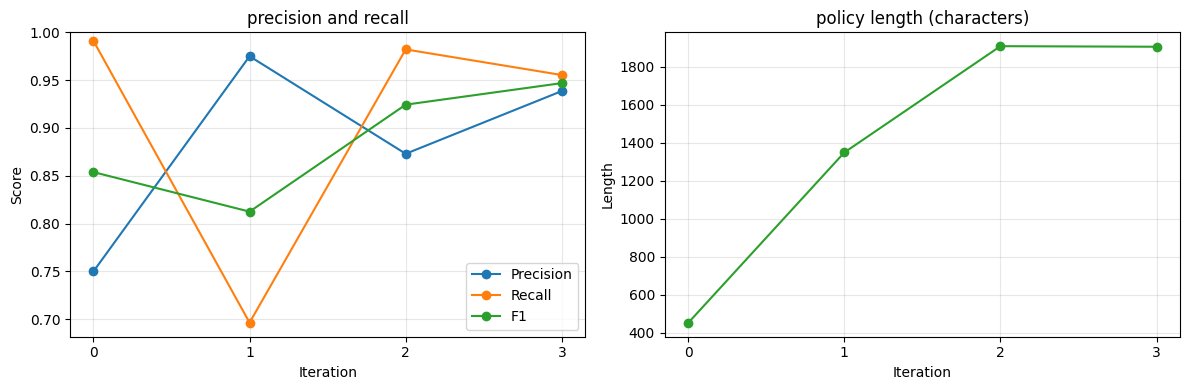

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(eval_df["iteration"], eval_df["precision"], marker="o", label="Precision", clip_on=False)
ax1.plot(eval_df["iteration"], eval_df["recall"], marker="o", label="Recall", clip_on=False)
ax1.plot(eval_df["iteration"], eval_df["f1"], marker="o", label="F1", clip_on=False)
ax1.set_ylim(top=1.0)
ax1.set(title="precision and recall", xlabel="Iteration", ylabel="Score")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(eval_df["iteration"], eval_df["length"], marker="o", color="tab:green")
ax2.set(title="policy length (characters)", xlabel="Iteration", ylabel="Length")
ax2.grid(alpha=0.3)

for ax in (ax1, ax2):
    ax.xaxis.get_major_locator().set_params(integer=True)  # integer ticks only

plt.tight_layout()
plt.show()

## Step 4: Human review for overfitting

In [30]:
# Initial policy
print(policies["text"].iloc[0])

You are a content moderator at AcornChat, an internet platform for squirrels.
Our policies are as follows:
-*Be kind:* Don't insult, threaten, or pile on other squirrels.
-*Keep locations private:* Don't share where food is stored or where a squirrel lives.
-*No raids:* Don't organize or encourage taking food from another squirrel's cache.
*No spam:* Don't advertise goods or services.
-*No fake danger:* Don't post false predator or hazard warnings.


In [31]:
# Final policy
print(policies["text"].iloc[-1])

You are a content moderator at AcornChat, an internet platform for squirrels. Moderate content according to the following rules:

- *Be kind:* Prohibited: insults, demeaning remarks, veiled/backhanded insults (e.g., "Not saying X is dumb, but..."), threats, harassment, speciesist/identity slurs (e.g., using "chipmunk" as an insult), group generalizations, passive-aggressive mockery, and telling squirrels to leave. Allowed: self-deprecating humor (including self-directed emojis like 🤡 or self-applied labels), affectionate ribbing and lighthearted banter between friends, general venting about behaviors/habits (not targeting identity groups), literal/positive references to actual chipmunks, and quoting abusive language solely to report bad behavior to mods.
- *Keep locations private:* Prohibited: disclosing, repeating, narrowing down, or hinting at another squirrel's (or their kits') drey, nest, hollow, or personal food cache under any circumstance—**including when quoting or reporting ru

## Step 5: Run on test data ("in production")

In [ ]:
# run final policy on test set
final_policy = policies["text"].iloc[-1]
test_results = classify(final_policy, df_test)

Job finished: JOB_STATE_SUCCEEDED


In [36]:
# report stats
pred = test_results["classification"].str.strip().eq("True")
truth = test_results["id"].map(df.set_index("id")["violation"]).astype(bool)
tp = (pred & truth).sum()
fp = (pred & ~truth).sum()
fn = (~pred & truth).sum()

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print(f"train: precision: {eval_df['precision'].iloc[-1]:.3f}; recall: {eval_df['recall'].iloc[-1]:.3f};  F1: {eval_df['f1'].iloc[-1]:.3f}")
print(f"test: precision: {precision:.3f};  recall: {recall:.3f};  F1: {f1:.3f}")

train: precision: 0.939; recall: 0.955;  F1: 0.947
test: precision: 0.944;  recall: 0.955;  F1: 0.949
